# Étape 7 — Conclusions, Mécanique Orbitale Képlérienne & Restitution Interactive

> **Référentiel méthodologique :** [Introduction à la Data Science — Étape 7 : Communication (*La Restitution & Data Storytelling*)](https://modules.apti.space/datascience/intro-datascience)  
> **Inspirations directes :** évolution physique exacte (résolution de l'équation de Kepler $M = E - e\sin E$ + Zone Habitable) et export *Universe Sandbox* de `notebooks/example/Exo-planet/kepler.ipynb`, directement branchés sur `/lakehouse/gold/exo_planets_clustered`.

---

## Synthèse Exécutive de notre Enquête *Data Detective*

Au terme des 7 étapes sur notre cluster **HDFS 3.5 + PySpark 4.2 + Delta Lake 4.4** :

1. **Raffinage Multi-Sources (Bronze $\rightarrow$ Silver)** : **39 954 solutions publiées** + **6 336 exoplanètes 2026** + **13 435 candidats Kepler/TESS** + **catalogue historique UAI** ont été consolidés sans aucune explosion N-M ni perte d'information sur les mécanismes d'absence **MAR** (*Transit* sans vitesse radiale vs *Doppler* sans rayon).
2. **Démystification du Biais de Découverte** :
   - La domination du **Transit (~75 %)** et une **période orbitale médiane de ~12 jours** ne signifient pas que l'Univers fabrique uniquement des mondes brûlants : la probabilité géométrique d'alignement $P_{\text{geom}} = R_\star / a$ chute à **$0{,}47\%$ à 1 UA**, tandis que la demi-amplitude Doppler de la Terre (**$0{,}09\text{ m/s}$**) demeure sous le plancher de bruit stellaire standard ($0{,}3\text{–}1\text{ m/s}$).
   - Seule la **Microlentille Gravitationnelle** sonde efficacement les planètes froides au-delà de la ligne des glaces ($1\text{–}6\text{ UA}$) à grande distance, et l'**Imagerie Directe** cible les jeunes géantes auto-lumineuses à $> 15\text{ UA}$.
3. **Architecture Physique des Mondes (K-Means $k=5$ & Loi Masse–Rayon)** :
   - Séparation nette en **5 archétypes** (*Jupiters Chaudes*, *Géantes Froides/Tempérées*, *Mini-Neptunes*, *Super-Terres Laviques*, *Telluriques Tempérées*), structurée par la **Vallée de Fulton ($\sim 1{,}8\,R_\oplus$)** et le **Désert des Neptunes Chaudes**.
   - Validation statistique (`Mann-Whitney`, $p \ll 10^{-10}$) de l'enrichissement en métaux `[Fe/H]` des étoiles hôtes de géantes gazeuses.
4. **Audit MLOps du Drift** : le passage des relevés Doppler pré-2009 à Kepler ($	ext{PSI} > 1{,}5$) puis à TESS/JWST prouve qu'un classifieur astronomique doit être ré-étalonné à chaque nouvelle mission spatiale.

In [ ]:
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

warnings.filterwarnings("ignore")

spark = (
    SparkSession.builder
    .appName("ExoPlanette_05_Conclusions_Orbits_Storytelling")
    .getOrCreate()
)

df_gold = spark.read.format("delta").load("/lakehouse/gold/exo_planets_clustered")
gold_pd = df_gold.toPandas()
print(f"Catalogue Gold chargé depuis HDFS : {len(gold_pd):,} exoplanètes confirmées.")

## 1. Classement des Meilleurs Mondes Potentiellement Habitables (Top ESI 2026)

Identifions dans notre couche Gold les planètes situées dans la **Zone Habitable Conservatrice de Kopparapu** ($0{,}35 \le S_{\text{eff}} \le 1{,}11\,S_\oplus$) de rayon tellurique ($R_p < 2{,}0\,R_\oplus$), triées par **Earth Similarity Index (`esi_score`)** et proximité à la Terre (cibles privilégiées du télescope spatial **JWST** en spectroscopie de transmission).

In [ ]:
top_habitable = (
    gold_pd[
        gold_pd["habitable_zone_status"].str.startswith("Conservatrice", na=False)
        & (gold_pd["radius_earth_est"] <= 2.0)
        & gold_pd["esi_score"].notna()
    ]
    .sort_values(["esi_score", "distance_parsec"], ascending=[False, True])
    .head(12)[[
        "planet_name", "host_star", "esi_score", "radius_earth_est", "mass_earth_est",
        "orbital_period_days", "equilibrium_temp_k_best", "distance_parsec",
        "star_temperature_k", "discovery_year", "n_transmission_spectra",
    ]]
)
print("=== TOP 12 DES MONDES TELLURIQUES EN ZONE HABITABLE CONSERVATRICE (PAR SCORE ESI) ===")
print(top_habitable.to_string(index=False))

=== TOP 12 DES MONDES TELLURIQUES EN ZONE HABITABLE CONSERVATRICE (PAR SCORE ESI) ===
       planet_name        host_star  esi_score  radius_earth_est  mass_earth_est  orbital_period_days  equilibrium_temp_k_best  distance_parsec  star_temperature_k  discovery_year  n_transmission_spectra
       Wolf 1069 b        Wolf 1069     0.9738             1.080           1.260            15.564000                   250.10         9.583410              3158.0            2023                     1.0
      TRAPPIST-1 e       TRAPPIST-1     0.9716             0.920           0.692             6.101013                   249.70        12.429889              2566.0            2017                     7.0
         GJ 1002 b          GJ 1002     0.9701             1.030           1.080            10.346500                   230.90         4.848670              3024.0            2022                     1.0
         TOI-700 d          TOI-700     0.9686             1.073           1.250            37.423

## 2. Mécanique Céleste Exacte : Orbites Elliptiques Képlériennes & Zone Habitable

Dans `notebooks/example/Exo-planet/kepler.ipynb`, l'anomalie excentrique était approximée au premier ordre ($E \approx M + e\sin M$). Nous implémentons ici le **solveur numérique exact de Newton-Raphson pour l'équation de Kepler** :
$$M(t) = E(t) - e \sin E(t), \qquad r(E) = a(1 - e\cos E), \qquad \tan\frac{\nu}{2} = \sqrt{\frac{1+e}{1-e}}\tan\frac{E}{2}$$
en plaçant l'étoile **au foyer réel $(0, 0)$** de chaque ellipse (centre géométrique décalé de $-a\cdot e$) et en superposant l'**anneau vert de la Zone Habitable Circumstellaire** ($[r_{\text{HZ,in}}, r_{\text{HZ,out}}]$) pour comparer visuellement **TRAPPIST-1** (7 planètes rocheuses en résonance autour d'une naine ultra-froide) et **55 Cancri / HD 110067 / Kepler-11** !

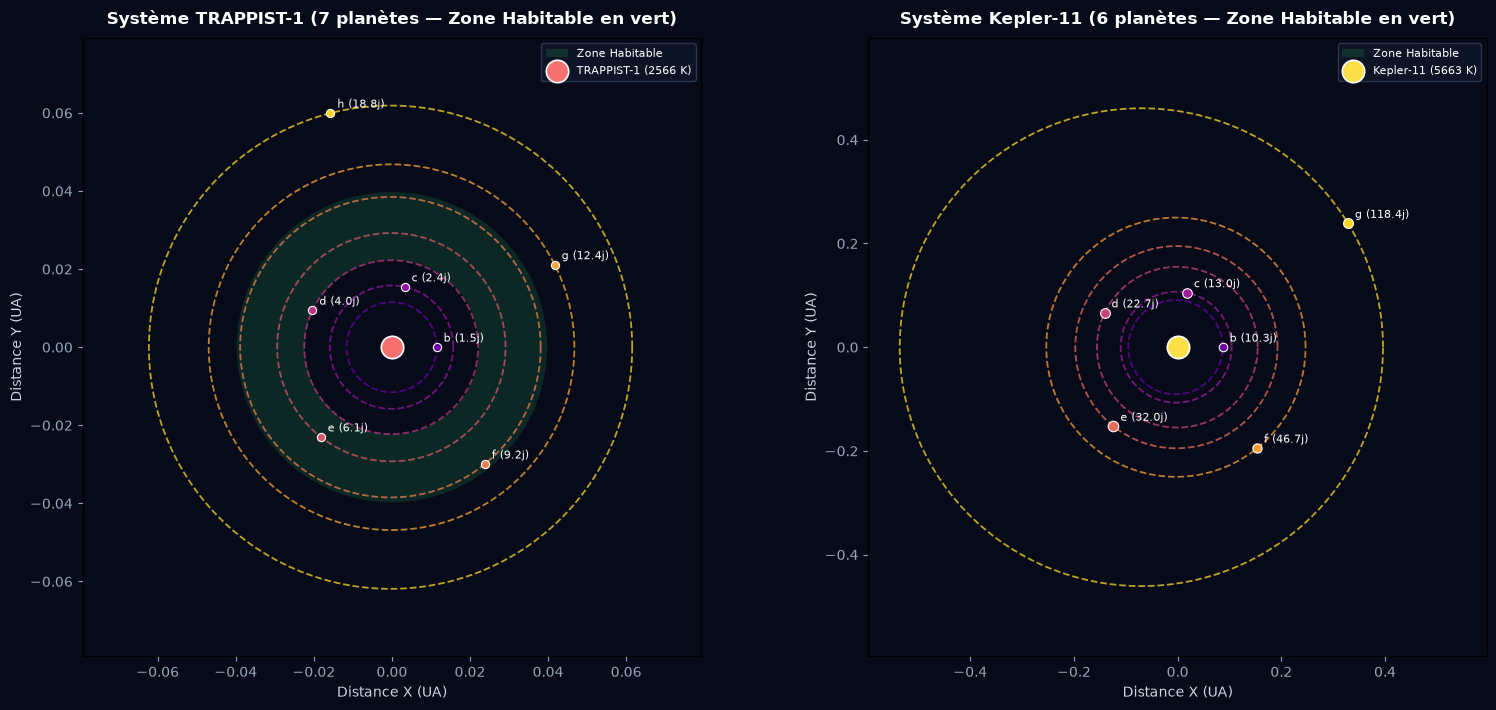

In [ ]:
def solve_kepler_newton(M, e, n_iter=8):
    """Résout M = E - e*sin(E) par itérations de Newton-Raphson vectorisées."""
    E = M + e * np.sin(M)
    for _ in range(n_iter):
        E = E - (E - e * np.sin(E) - M) / (1.0 - e * np.cos(E))
    return E


def star_blackbody_hex(teff):
    if pd.isna(teff):
        return "#fde047"
    if teff >= 7500:
        return "#93c5fd"
    if teff >= 6000:
        return "#f8fafc"
    if teff >= 5200:
        return "#fde047"
    if teff >= 3700:
        return "#fb923c"
    return "#f87171"


def plot_planetary_system_kepler(df_all, host_name, ax):
    sys_df = (
        df_all[df_all["host_star"] == host_name]
        .dropna(subset=["semi_major_axis_au_best", "orbital_period_days"])
        .sort_values("semi_major_axis_au_best")
    )
    ax.set_facecolor("#070b19")
    ax.set_aspect("equal")

    # Zone Habitable (anneau entre hz_inner_au et hz_outer_au)
    hz_in = sys_df["hz_inner_au"].dropna().iloc[0] if sys_df["hz_inner_au"].notna().any() else None
    hz_out = sys_df["hz_outer_au"].dropna().iloc[0] if sys_df["hz_outer_au"].notna().any() else None
    max_a = float(sys_df["semi_major_axis_au_best"].max())
    lim = max(max_a * 1.28, (hz_out * 1.15) if (hz_out and hz_out < max_a * 2.2) else max_a * 1.28)

    if hz_in and hz_out:
        hz_ring = patches.Wedge((0, 0), hz_out, 0, 360, width=max(hz_out - hz_in, 1e-4), facecolor="#22c55e", alpha=0.16, label="Zone Habitable")
        ax.add_patch(hz_ring)

    # Étoile au foyer (0, 0)
    teff = sys_df["star_temperature_k"].dropna().iloc[0] if sys_df["star_temperature_k"].notna().any() else 5778
    ax.scatter([0], [0], s=260, color=star_blackbody_hex(teff), edgecolor="white", linewidth=1.2, zorder=12, label=f"{host_name} ({teff:.0f} K)")

    theta_grid = np.linspace(0, 2 * np.pi, 240)
    cmap = plt.cm.plasma(np.linspace(0.2, 0.92, len(sys_df)))

    for idx, (_, row) in enumerate(sys_df.iterrows()):
        a = float(row["semi_major_axis_au_best"])
        e = float(row["eccentricity"]) if pd.notna(row["eccentricity"]) and 0 <= row["eccentricity"] < 0.95 else 0.0
        E_grid = solve_kepler_newton(theta_grid, e)
        x_orb = a * (np.cos(E_grid) - e)
        y_orb = a * np.sqrt(1.0 - e**2) * np.sin(E_grid)
        ax.plot(x_orb, y_orb, "--", color=cmap[idx], alpha=0.75, lw=1.3)

        # Position instantanée répartie par phase
        M0 = (idx * 1.35) % (2 * np.pi)
        E0 = float(solve_kepler_newton(np.array([M0]), e)[0])
        xp = a * (np.cos(E0) - e)
        yp = a * np.sqrt(1.0 - e**2) * np.sin(E0)
        rp = float(row["radius_earth_est"]) if pd.notna(row["radius_earth_est"]) else 1.5
        marker_sz = np.clip(28.0 * np.sqrt(rp), 35, 240)
        ax.scatter([xp], [yp], s=marker_sz, color=cmap[idx], edgecolor="white", lw=0.8, zorder=15)
        short_lbl = str(row["planet_letter"] or row["planet_name"].split()[-1])
        ax.annotate(f"{short_lbl} ({row['orbital_period_days']:.1f}j)", (xp, yp), xytext=(5, 4), textcoords="offset points", color="white", fontsize=8)

    ax.set_xlim(-lim, lim)
    ax.set_ylim(-lim, lim)
    ax.set_xlabel("Distance X (UA)", color="#cbd5e1")
    ax.set_ylabel("Distance Y (UA)", color="#cbd5e1")
    ax.tick_params(colors="#94a3b8")
    ax.set_title(f"Système {host_name} ({len(sys_df)} planètes — Zone Habitable en vert)", color="white", fontweight="bold", pad=10)
    ax.legend(loc="upper right", facecolor="#0f172a", edgecolor="#334155", labelcolor="white", fontsize=8)


fig, axes = plt.subplots(1, 2, figsize=(16, 7.2), facecolor="#070b19")
plot_planetary_system_kepler(gold_pd, "TRAPPIST-1", axes[0])
plot_planetary_system_kepler(gold_pd, "Kepler-11", axes[1])
plt.tight_layout()
plt.show()

## 3. Export d'un Système Planétaire vers *Universe Sandbox* & Audit Final de la Couche Gold

Fidèle à l'outil d'export de `kepler.ipynb`, la fonction ci-dessous convertit n'importe quel système de `/lakehouse/gold/exo_planets_clustered` en unités SI internationales (`kg`, `m`, vitesse orbitale périhélique $v_p = \sqrt{\frac{G M_\star}{a}\frac{1+e}{1-e}}$) au format JSON, exactement tel qu'exposé en 1 clic dans notre **Dashboard Streamlit (`http://localhost:8501`)**.

In [ ]:
def build_universe_sandbox_payload(df_all: pd.DataFrame, host_name: str) -> dict:
    AU_M = 1.495978707e11
    SOLAR_MASS_KG = 1.98847e30
    SOLAR_RAD_M = 6.9634e8
    EARTH_MASS_KG = 5.9722e24
    EARTH_RAD_M = 6.371e6
    G_SI = 6.67430e-11

    sys_df = df_all[df_all["host_star"] == host_name].dropna(subset=["semi_major_axis_au_best", "orbital_period_days"]).sort_values("semi_major_axis_au_best")
    m_star = float(sys_df["star_mass_solar"].dropna().iloc[0]) if sys_df["star_mass_solar"].notna().any() else 1.0
    r_star = float(sys_df["star_radius_solar"].dropna().iloc[0]) if sys_df["star_radius_solar"].notna().any() else 1.0
    t_star = float(sys_df["star_temperature_k"].dropna().iloc[0]) if sys_df["star_temperature_k"].notna().any() else 5778.0

    payload = {
        "system_name": host_name,
        "source": "HDFS Delta Lake Gold (/lakehouse/gold/exo_planets_clustered)",
        "star": {
            "name": host_name,
            "mass_kg": m_star * SOLAR_MASS_KG,
            "radius_m": r_star * SOLAR_RAD_M,
            "temperature_k": t_star,
            "position_m": [0.0, 0.0, 0.0],
            "velocity_ms": [0.0, 0.0, 0.0],
        },
        "planets": [],
    }

    for _, row in sys_df.iterrows():
        a_m = float(row["semi_major_axis_au_best"]) * AU_M
        e = float(row["eccentricity"]) if pd.notna(row["eccentricity"]) and 0 <= row["eccentricity"] < 0.95 else 0.0
        mp_kg = float(row["mass_earth_est"] if pd.notna(row["mass_earth_est"]) else 1.0) * EARTH_MASS_KG
        rp_m = float(row["radius_earth_est"] if pd.notna(row["radius_earth_est"]) else 1.0) * EARTH_RAD_M
        r_peri = a_m * (1.0 - e)
        v_peri = float(np.sqrt((G_SI * m_star * SOLAR_MASS_KG / a_m) * ((1.0 + e) / (1.0 - e))))
        payload["planets"].append({
            "name": str(row["planet_name"]),
            "archetype": str(row["planet_archetype"]),
            "mass_kg": mp_kg,
            "radius_m": rp_m,
            "semi_major_axis_au": float(row["semi_major_axis_au_best"]),
            "orbital_period_days": float(row["orbital_period_days"]),
            "eccentricity": e,
            "perihelion_position_m": [r_peri, 0.0, 0.0],
            "perihelion_velocity_ms": [0.0, v_peri, 0.0],
        })
    return payload


trappist_json = build_universe_sandbox_payload(gold_pd, "TRAPPIST-1")
print(f"Export JSON Universe Sandbox prêt pour {trappist_json['system_name']} : {len(trappist_json['planets'])} planètes.")
print("Exemple 1re planète :", json.dumps(trappist_json["planets"][0], indent=2, ensure_ascii=False))

# Inventaire complet de la couche Gold pour le Dashboard Streamlit (:8501)
jvm = spark._jvm
fs = jvm.org.apache.hadoop.fs.FileSystem.get(spark._jsc.hadoopConfiguration())
PathHDFS = jvm.org.apache.hadoop.fs.Path
gold_root = PathHDFS("/lakehouse/gold")

exo_gold_tables = sorted([
    s.getPath().getName()
    for s in fs.listStatus(gold_root)
    if s.isDirectory()
    and s.getPath().getName().startswith("exo_")
    and fs.exists(PathHDFS(s.getPath(), "_delta_log"))
])

assert len(exo_gold_tables) >= 7, f"Attendu >= 7 tables Gold exo_*, trouvé : {exo_gold_tables}"
print("\n=== INVENTAIRE FINAL DES TABLES DELTA GOLD SUR HDFS POUR STREAMLIT (:8501) ===")
for tbl in exo_gold_tables:
    cnt = spark.read.format("delta").load(f"/lakehouse/gold/{tbl}").count()
    print(f" - /lakehouse/gold/{tbl:<28} : {cnt:>8,} lignes")

Export JSON Universe Sandbox prêt pour TRAPPIST-1 : 7 planètes.
Exemple 1re planète : {
  "name": "TRAPPIST-1 b",
  "archetype": "Super-Terre Chaude / Lavique",
  "mass_kg": 8.2058028e+24,
  "radius_m": 7110036.000000001,
  "semi_major_axis_au": 0.01154,
  "orbital_period_days": 1.510826,
  "eccentricity": 0.00622,
  "perihelion_position_m": [
    1715621472.236599,
    0.0,
    0.0
  ],
  "perihelion_velocity_ms": [
    0.0,
    83605.7770841937,
    0.0
  ]
}

=== INVENTAIRE FINAL DES TABLES DELTA GOLD SUR HDFS POUR STREAMLIT (:8501) ===


 - /lakehouse/gold/exo_candidates_summary       :        4 lignes


 - /lakehouse/gold/exo_cluster_profiles         :        5 lignes


 - /lakehouse/gold/exo_discovery_timeline       :      141 lignes


 - /lakehouse/gold/exo_drift_audit              :       15 lignes


 - /lakehouse/gold/exo_methods_bias             :       11 lignes


 - /lakehouse/gold/exo_planets_clustered        :    6,336 lignes


 - /lakehouse/gold/exo_stats_tests              :        4 lignes


 - /lakehouse/gold/exo_tess_lightcurves         :       50 lignes
